# Analysis of difference Zstar and HYCOM1

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib

In [2]:
matplotlib.rcParams.update({"font.size": 16})

In [3]:
zstar_dir = "/scratch4/NCEPDEV/marine/Raphael.Dussin/freeruns_mom6sis2_GLBb008/GLBb008_mom6sis2_ERA5_zstar"
hycom1_dir = "/scratch4/NCEPDEV/marine/Raphael.Dussin/freeruns_mom6sis2_GLBb008/GLBb008_mom6sis2_ERA5_hycom1"

In [4]:
zstar_scalar = xr.open_mfdataset(f"{zstar_dir}/*ocean_scalar_month.nc")
hycom1_scalar = xr.open_mfdataset(f"{hycom1_dir}/*ocean_scalar_month.nc")

In [5]:
def compare_timeseries(ds0, ds1, var="thetaoga", labels=["z*", "hycom1"]):
    """ compare timeseries """
    plt.figure()
    ax = plt.axes()
    ds0[var].plot(ax=ax, label=labels[0])
    ds1[var].plot(ax=ax, label=labels[1])
    plt.legend()
    ax.grid()
    ax.set_title(f"Comparing {var}")
    return None

## Temperature

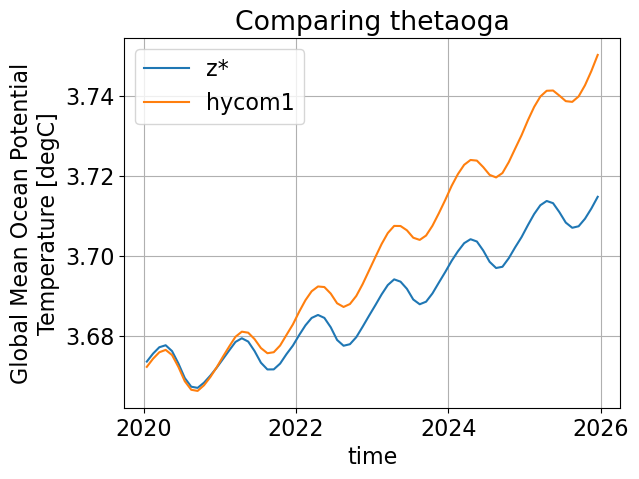

In [6]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="thetaoga", labels=["z*", "hycom1"])

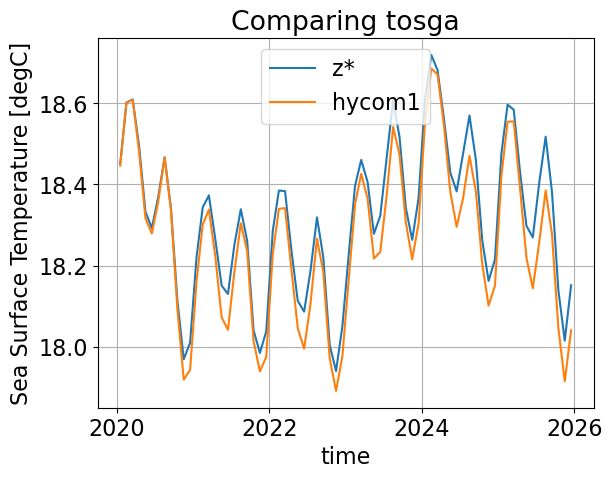

In [7]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="tosga", labels=["z*", "hycom1"])

## Sea surface height

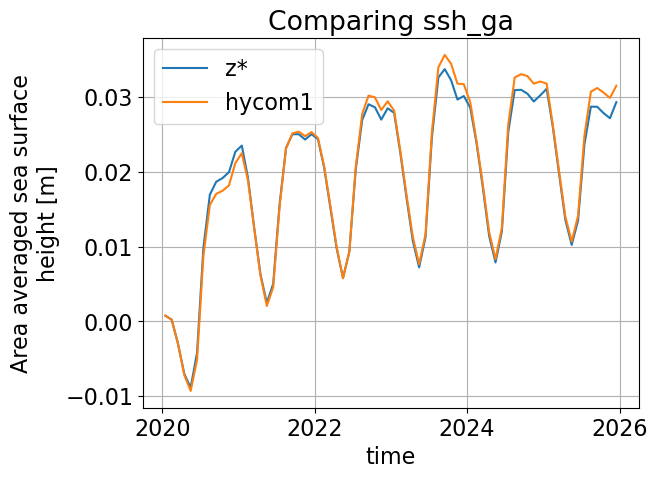

In [8]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="ssh_ga", labels=["z*", "hycom1"])

## Salinity

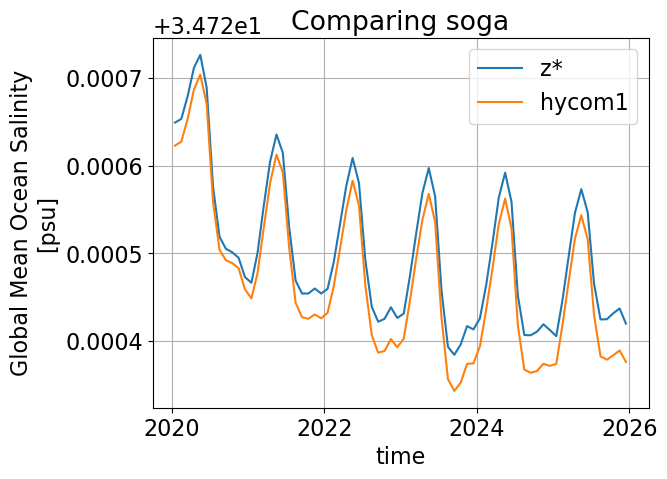

In [9]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="soga", labels=["z*", "hycom1"])

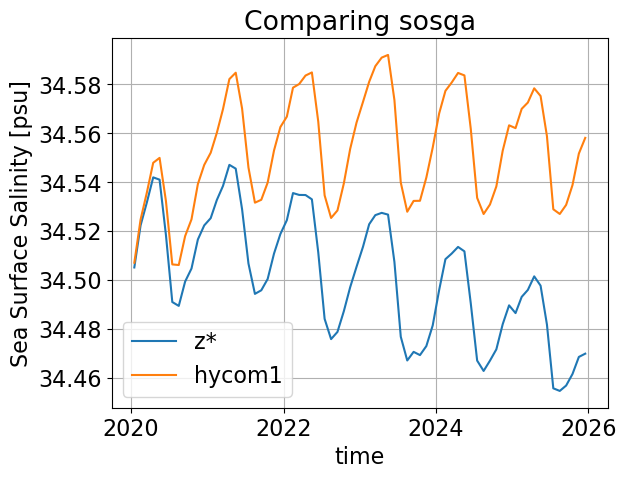

In [10]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="sosga", labels=["z*", "hycom1"])

## heat fluxes

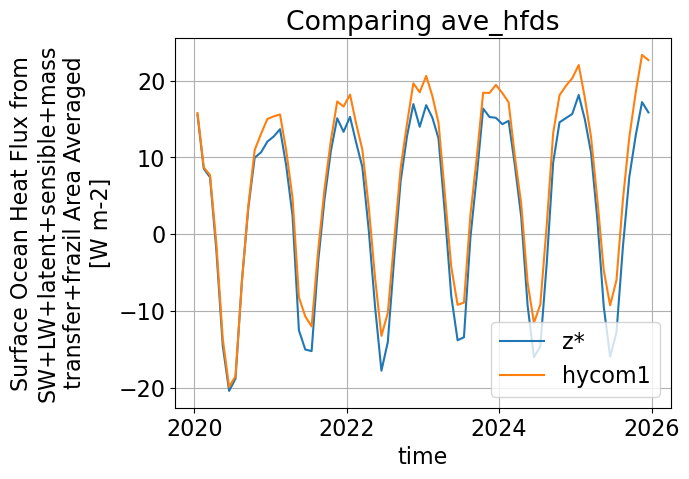

In [11]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="ave_hfds", labels=["z*", "hycom1"])

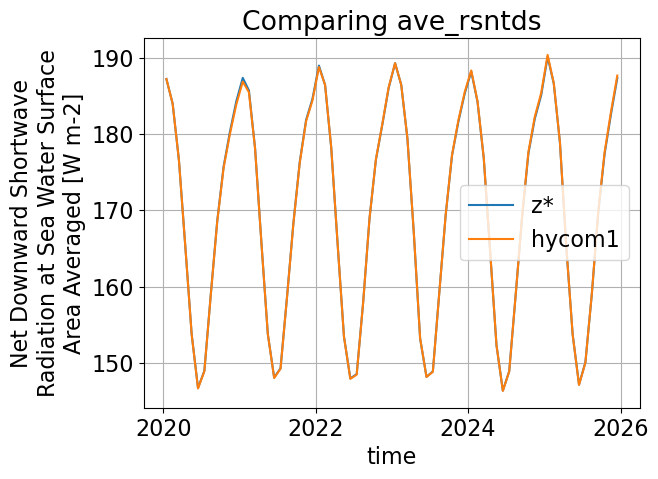

In [12]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="ave_rsntds", labels=["z*", "hycom1"])

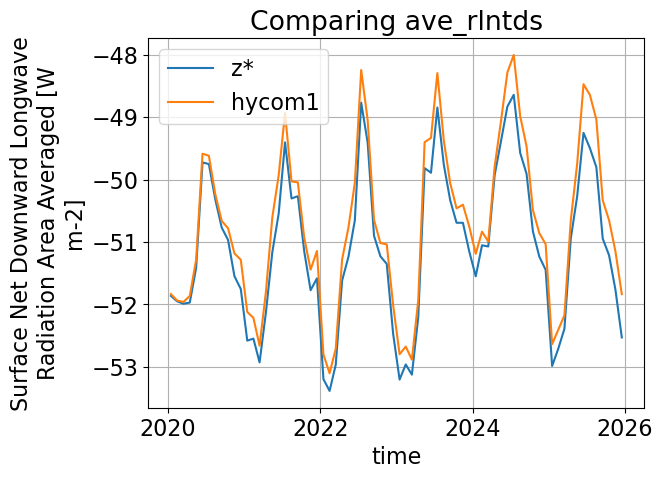

In [13]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="ave_rlntds", labels=["z*", "hycom1"])

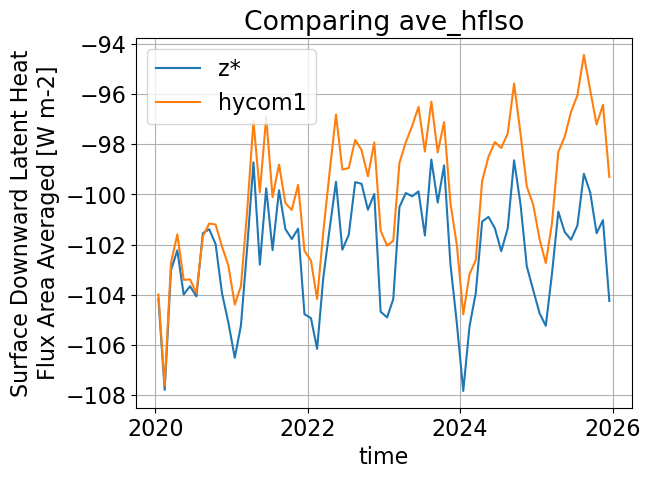

In [14]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="ave_hflso", labels=["z*", "hycom1"])

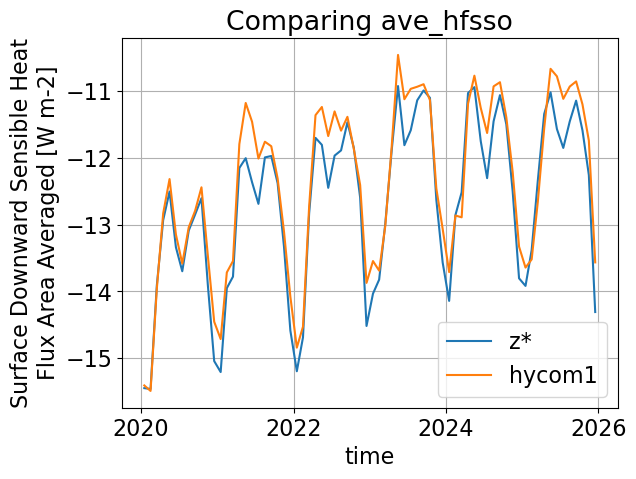

In [15]:
compare_timeseries(zstar_scalar, hycom1_scalar, var="ave_hfsso", labels=["z*", "hycom1"])

In [16]:
zstar_3d = xr.open_mfdataset(f"{zstar_dir}/*ocean_month_z.nc")
hycom1_3d = xr.open_mfdataset(f"{hycom1_dir}/*ocean_month_z.nc")

In [17]:
def tridepth_plot(da, vmin=None, vmax=None, cmap="RdBu_r", cbar_ticks=[], cbar_label="", title=""):
    """ my tri-depth plot for drift """

    f, (a0, a1, a2) = plt.subplots(3, 1, height_ratios=[1, 2, 2], figsize=(12,8))
    kwargs = dict(yincrease=False, xincrease=True,
                  vmin=vmin, vmax=vmax,
                  cmap=cmap, add_labels=False, add_colorbar=False)
    C = da.plot(ax=a0, y="z_l", ylim=[200,0], **kwargs)
    da.plot(ax=a1, y="z_l", ylim=[1000,200], **kwargs)
    da.plot(ax=a2, y="z_l", ylim=[6000,1000], **kwargs)

    for ax in [a0, a1]:
        t = ax.get_xticks()
        ax.set_xticklabels([])
        ax.set_xlabel("")
    for ax in [a0, a2]:
        ax.set_ylabel("")
    for ax in [a1, a2]:
        ax.set_title("")

    a1.set_ylabel("Depth [meters]", fontsize=20)
    #if "latitude" in da.dims:
    #    a2.set_xlabel(r"Latitude [$^{\circ}$N]", fontsize=20)
    #elif "longitude" in da.dims:
    #    a2.set_xlabel(r"Longitude [$^{\circ}$E]", fontsize=20)
    a0.set_title("")

    cb_ax = f.add_axes([0.92, 0.08, 0.04, 0.80])
    cb = f.colorbar(C, cax=cb_ax)
    cb.set_ticks(cbar_ticks)
    cb.set_ticklabels(cbar_ticks)
    cb.set_label(cbar_label, fontsize=20)
    cb.ax.tick_params(labelsize=16)
    a0.set_facecolor([0.3,0.3,0.3])
    a1.set_facecolor([0.3,0.3,0.3])
    a2.set_facecolor([0.3,0.3,0.3])
    #f.set_facecolor("cornsilk")
    f.suptitle(title, fontsize=22)
    return f

def plot_profile_drift(ds, var="thetao_xyave", cbar_label="",
                       vmin=None, vmax=None, cbar_ticks=[], title=None):
    # create yearly array
    yearly = ds[var].resample(time="1YS").mean(dim="time")
    # plot
    f = tridepth_plot(yearly - yearly.isel(time=0),
                      cbar_label=cbar_label,
                      vmin=vmin, vmax=vmax,
                      cbar_ticks=cbar_ticks, title=title)
    plt.show()

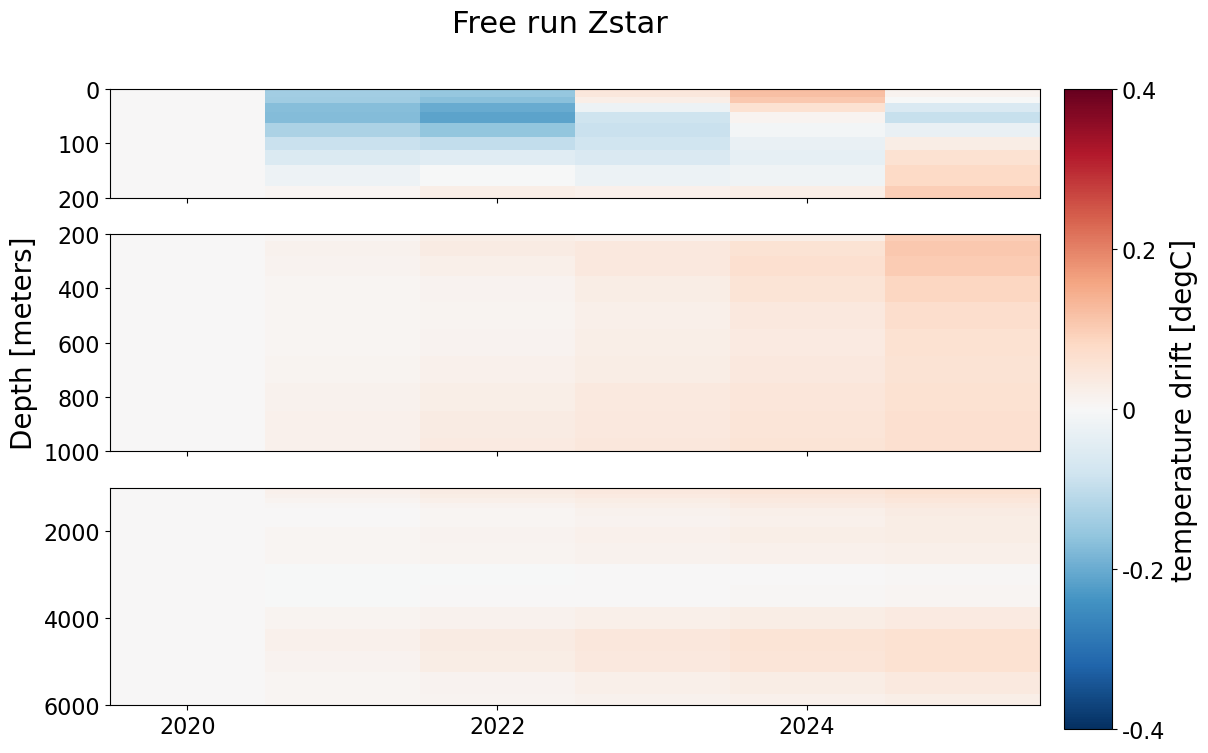

In [18]:
plot_profile_drift(zstar_3d.sel(time=slice("2020-01", "2025-12")), var="thetao_xyave",
                   cbar_label="temperature drift [degC]",
                   vmin=-0.4, vmax=0.4,
                   cbar_ticks=[-0.4,-0.2, 0, 0.2, 0.4],
                   title="Free run Zstar")

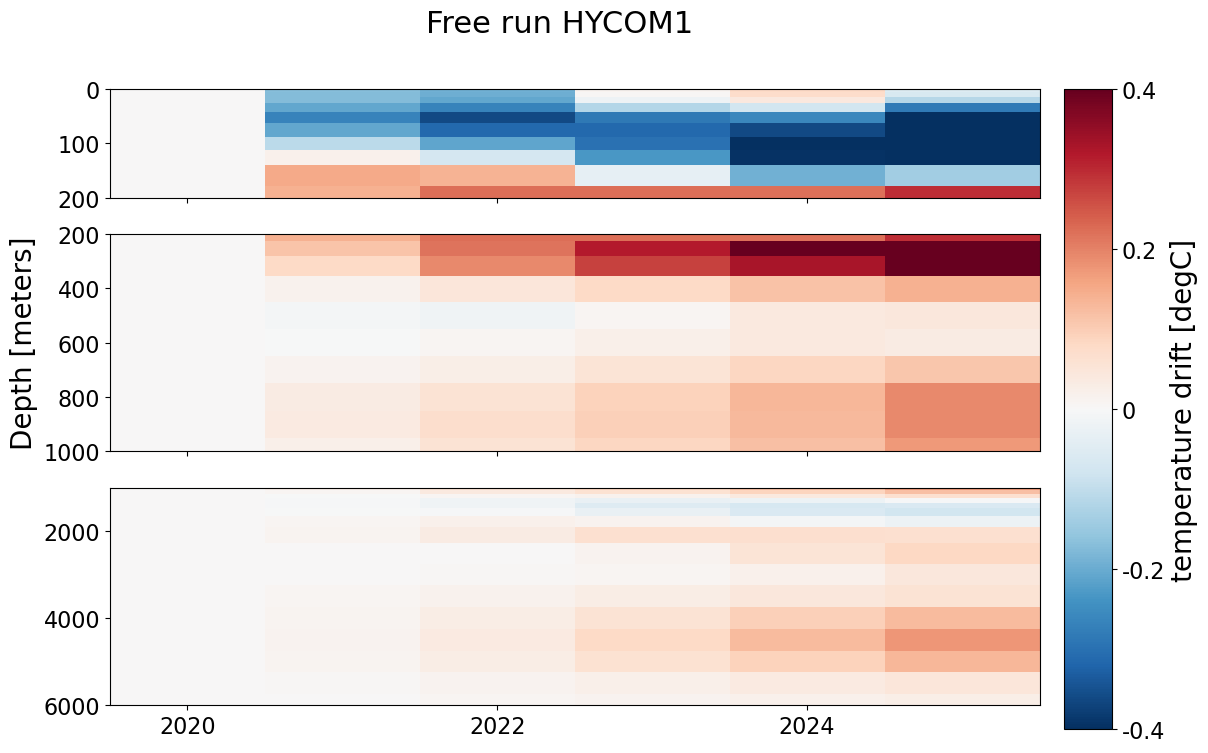

In [19]:
plot_profile_drift(hycom1_3d.sel(time=slice("2020-01", "2025-12")), var="thetao_xyave",
                   cbar_label="temperature drift [degC]",
                   vmin=-0.4, vmax=0.4,
                   cbar_ticks=[-0.4,-0.2, 0, 0.2, 0.4],
                   title="Free run HYCOM1")

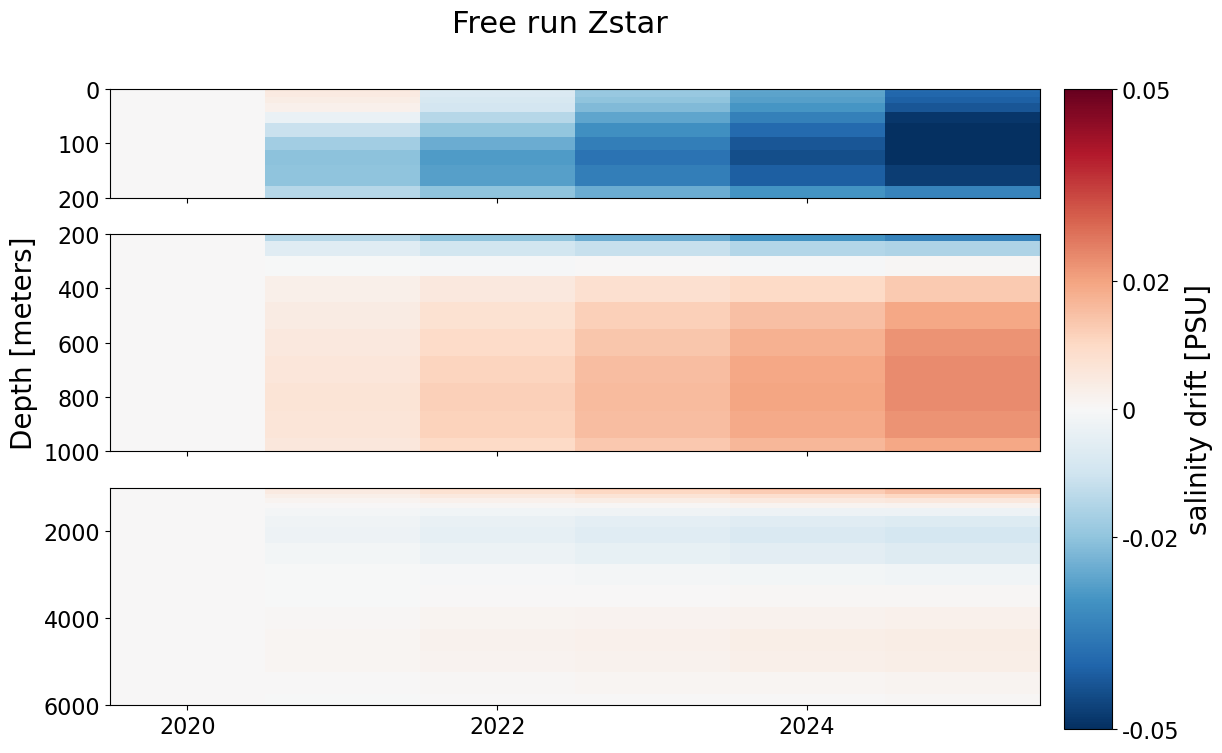

In [20]:
plot_profile_drift(zstar_3d.sel(time=slice("2020-01", "2025-12")), var="so_xyave",
                   cbar_label="salinity drift [PSU]",
                   vmin=-0.05, vmax=0.05,
                   cbar_ticks=[-0.05,-0.02, 0, 0.02, 0.05],
                   title="Free run Zstar")

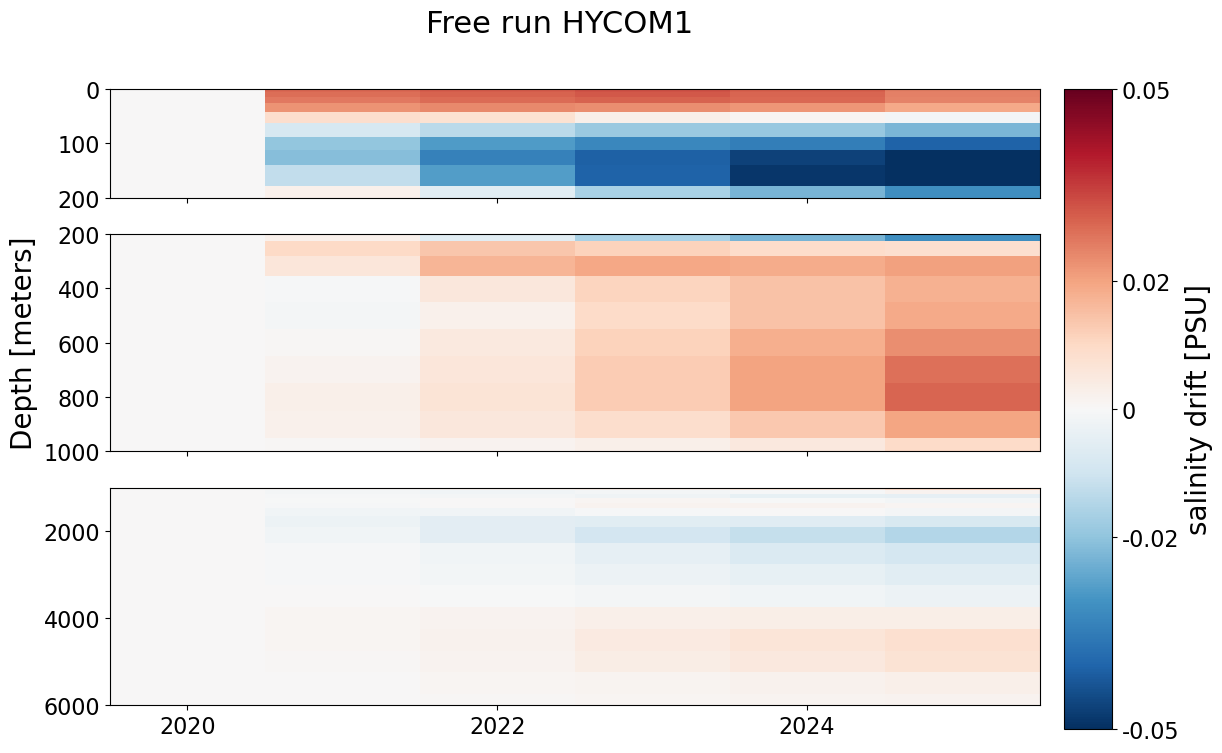

In [21]:
plot_profile_drift(hycom1_3d.sel(time=slice("2020-01", "2025-12")), var="so_xyave",
                   cbar_label="salinity drift [PSU]",
                   vmin=-0.05, vmax=0.05,
                   cbar_ticks=[-0.05,-0.02, 0, 0.02, 0.05],
                   title="Free run HYCOM1")